# Hubble: gradient-based refinement vs differential evolution

This notebook tests whether the differential-evolution (DE) stage of the Hubble pipeline (`hubbletilus_noise.ipynb`) can be replaced by L-BFGS-B driven by gradients from Optiland's PyTorch backend. Three refiners are run on the same noisy observations:

1. **L-BFGS-B with autodiff gradients** (torch backend), started from `x0` and from `N_STARTS - 1` Latin-hypercube points inside the DE bounds;
2. **L-BFGS-B with finite-difference gradients** (numpy backend), from the same starts, to separate the value of a gradient method from the value of autodiff. Two variants: SciPy's default forward differences (`eps=1e-8`, which is also what DE's polishing step uses) and central differences (`jac="3-point"`, step about $6\times10^{-6}$ in scaled units);
3. **DE** with the settings of the thesis run (`best1bin`, popsize 15, `tol=1e-12`, start `x0`, L-BFGS-B polishing), but for `DE_MAXITER` generations.

**Optiland fix.** In Optiland 0.6.0, `ChiefRayStrategy._create_spherical_ref` converts the reference-sphere center (the chief ray's image point) and radius to Python floats with `.item()`. Autodiff then treats the reference sphere as fixed, and the decenter and tilt gradients come out wrong (Section 2). The notebook replaces that method at runtime with one that keeps them as tensors; the installed package is not modified.

**Data.** The noise realization of the thesis run was not saved (`genpsfn` draws unseeded noise), so a new realization with the same $\sigma$ is drawn with a fixed seed and used by all three methods. `x0` and the DE bounds are taken from the Nautilus run in `hubbletilus_noise.ipynb`. At this noise level the noise has no material effect on the likelihood (thesis Chapter 5), so they apply equally to the new realization.

**Runtime.** One evaluation of the DE objective (five PSFs) takes about 0.05 s with numpy, so one DE generation of 75 members takes about 4 s and `DE_MAXITER = 300` about 20 minutes. The thesis run used 2000 generations. One autodiff evaluation (forward and backward) takes about 0.2 s. With the default settings the whole notebook takes about 40 minutes.

## 1. Setup

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.optimize import differential_evolution, minimize
from scipy.special import j1, jv
from scipy.stats import qmc

import optiland.backend as be
from optiland import optic, physical_apertures
from optiland.psf import MMDFTPSF
from optiland.wavefront import OPD, strategy
from optiland.wavefront.reference_geometry import SphericalReference

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4g}".format)

NAMES = ["sdx", "sdy", "sdz", "stx", "sty"]
FIELDS = [(0, 0), (0, 1), (1, 0), (1, 1), (-1, -1)]
TRUTH = np.array([52.22, -113.86, 38.99, 0.13, -0.04])

# From hubbletilus_noise.ipynb (cells 17 and 21): weighted median and 2.1%-97.9%
# weighted quantiles of the final 100 Nautilus samples.
X0 = np.array([51.06, -0.66, 39.60, 0.12, -0.04])
BOUNDS = np.array([(-155.77, 171.13), (-183.11, 194.86), (36.05, 42.66), (0.10, 0.14), (-0.06, -0.03)])

# Thesis DE result (solutions_log_noise.txt, generation 2000), from a different noise realization.
DE_THESIS = np.array([53.7673974, -110.035201, 39.0723720, 0.129587262, -0.0398492377])

SIGMA = 0.01        # per-pixel noise, as in genpsfn
NOISE_SEED = 2026
START_SEED = 3
DE_SEED = 1
N_STARTS = 8        # x0 plus N_STARTS - 1 Latin-hypercube starts
DE_MAXITER = 300    # the thesis run used 2000 (about 2 h here)
LBFGS_OPTIONS = dict(maxiter=500, maxfun=1000, ftol=1e-15, gtol=1e-12)

The circular-Bessel basis functions below are copied unchanged from `hubbletilus_noise.ipynb`. The projection reproduces `decompose_psf_cached` exactly.

In [2]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(np.ceil((-1 + np.sqrt(1 + 8 * j)) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(np.floor(n / 2.))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=128, rho=None, theta=None, outside=np.nan, zero=19.053609871416903, **kwargs):
 
    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*np.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.cos(np.abs(m) * theta)
    else:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.sin(np.abs(m) * theta)
    return cb_result


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in circbessel1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = np.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output

In [3]:
_x = (np.arange(64, dtype=np.float64) - (64 - 1) / 2.0) / 19.053609871416903
_xx, _yy = np.meshgrid(_x, _x)
BASIS = basis_vectors(nterms=15, rho=np.sqrt(_xx**2 + _yy**2), theta=np.arctan2(_yy, _xx)).reshape(15, -1)
NORM = np.einsum("ij,ij->i", BASIS, BASIS)

`hubble()` is the model from `hubbletilus_noise.ipynb`, except that the tilts are converted with `* np.pi / 180` instead of `np.deg2rad`, which does not accept tensors that require gradients. The arguments are reordered so that the misalignment comes first.

In [4]:
def hubble(sdx=0, sdy=0, sdz=0, stx=0, sty=0, WL=0.55):

    K=1000 #mm to micron
    #Hubble
    hubble = optic.Optic(name="Hubble")

    hubble.add_surface(index=0, radius=np.inf, thickness=np.inf)

    # add physical aperture in primary mirror
    obscuration = physical_apertures.RadialAperture(r_max=1200, r_min=384)
    c1 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=0, offset_y=1000)
    c2 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=-707.15, offset_y=-707.15)
    c3 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=707.15, offset_y=-707.15)
    r1 = physical_apertures.RectangularAperture(x_min=-19, x_max=19, y_min=-1200, y_max=1200)
    r2 = physical_apertures.RectangularAperture(x_min=-1200, x_max=1200, y_min=-19, y_max=19)

    ap = obscuration - r1 - r2 -c1 - c2 - c3

    hubble.add_surface(
        index=1,
        x=0.0, y=0.0, z=0,   # paraxial / entrance reference
    )

    hubble.add_surface(
        index=2,
        radius=-11040.02286,
        x=0.0, y=0.0, z=4910.01016,
        material="mirror",
        is_stop=True,
        conic=-1.001152,
        aperture=ap,
    )

    hubble.add_surface(
        index=3,
        radius=-1349.31166,
        x=sdx / K,
        y=sdy / K,
        z=0 + sdz / K,              # independent M2 piston
        rx=stx * np.pi / 180,       # np.deg2rad rejects tensors that require grad
        ry=sty * np.pi / 180,
        material="mirror",
        conic=-1.483014,
    )

    hubble.add_surface(
        index=4,
        radius=-635.38227,
        x=0.0, y=0.0, z=6365.20955,         # image fixed while M2 moves
    )

    hubble.set_aperture(aperture_type="EPD", value=2400)

    hubble.set_field_type(field_type="angle")
    hubble.add_field(y=0.)
    hubble.add_field(y=0.038)
    hubble.add_field(y=-0.038)

    hubble.add_wavelength(value=WL, is_primary=True)

    return hubble

In [5]:
_OPTILAND_REF = strategy.ChiefRayStrategy._create_spherical_ref


def _create_spherical_ref(self, x, y, z):
    # Optiland's version without .item(), so the reference sphere stays in the autodiff graph
    R = be.sqrt(x**2 + y**2 + (z - self.pupil_z) ** 2)
    return SphericalReference((x.reshape(()), y.reshape(()), z.reshape(())), R.reshape(()))


def use_numpy():
    be.set_backend("numpy")
    strategy.ChiefRayStrategy._create_spherical_ref = _OPTILAND_REF


def use_torch(fix_reference=True):
    be.set_backend("torch")
    be.set_precision("float64")
    be.grad_mode.enable()
    strategy.ChiefRayStrategy._create_spherical_ref = _create_spherical_ref if fix_reference else _OPTILAND_REF


def coeffs(theta, field):
    # genpsf: circular-Bessel coefficients of the central 64x64 patch of the PSF
    psf = MMDFTPSF(hubble(*theta), field=field, wavelength=0.55, grid_size=64).psf
    patch = psf[96:160, 96:160].reshape(-1)
    return (be.array(BASIS) @ patch) / be.array(NORM)


def cost(theta, obs):
    # lstep: sum of squared coefficient residuals over the five fields
    return sum(be.sum((coeffs(theta, f) - be.array(o)) ** 2) for f, o in zip(FIELDS, obs))


def wfe(theta):
    # on-axis RMS WFE (waves) of the residual system TRUTH - theta, as in the thesis
    use_numpy()
    nominal = OPD(hubble(), field=(0, 0), wavelength=0.55).generate_opd_map()["z"]
    residual = OPD(hubble(*(TRUTH - theta)), field=(0, 0), wavelength=0.55).generate_opd_map()["z"]
    return np.nanstd(nominal - residual)


# L-BFGS-B works in coordinates scaled to [0, 1] across the DE bounds, so that
# micrometers and degrees have comparable step sizes.
LO, WIDTH = BOUNDS[:, 0], BOUNDS[:, 1] - BOUNDS[:, 0]
to_theta = lambda u: LO + np.asarray(u) * WIDTH
to_u = lambda theta: (np.asarray(theta) - LO) / WIDTH

Noisy observations at the injected truth, drawn as in `genpsfn` but with a fixed seed.

In [6]:
use_numpy()
rng = np.random.default_rng(NOISE_SEED)
OBS = []
for f in FIELDS:
    psf = MMDFTPSF(hubble(*TRUTH), field=f, wavelength=0.55, grid_size=64).psf[96:160, 96:160]
    OBS.append((BASIS @ (psf + rng.normal(0, SIGMA, psf.shape)).reshape(-1)) / NORM)
OBS = np.array(OBS)

Noise predictions from `noise_analysis.py` (thesis Chapter 5). In the linear model, moving the estimate by one noise standard deviation raises $S$ by between $\lambda_{\min}$ and $\lambda_{\max}$, depending on the direction ($\lambda$ are the eigenvalues of $\mathbf{L}^\top\mathbf{J}^\top\mathbf{J}\mathbf{L}$, with $\mathrm{Cov}=\mathbf{L}\mathbf{L}^\top$). Two solutions whose costs differ by less than `DS_TOL` $=0.01\,\lambda_{\min}$ are within $0.1\sigma$ of each other in every direction; this is the threshold used below to say that a method has reached the best solution.

In [7]:
na = np.load("noise_analysis.npz")
SIG = na["hubble_sig_theta"]     # noise-limited s.d. of the least-squares estimate
COV = na["hubble_cov"]
COV_INV = np.linalg.inv(COV)
L = np.linalg.cholesky(COV)
DS_1SIG = np.linalg.eigvalsh(L.T @ na["hubble_J"].T @ na["hubble_J"] @ L)
DS_TOL = 0.01 * DS_1SIG.min()

print(f"S at the truth: {cost(TRUTH, OBS):.3e} (expected minimum {na['hubble_floor']:.2e})")
print(f"S rises by {DS_1SIG.min():.2e} to {DS_1SIG.max():.2e} for a 1-sigma error; DS_TOL = {DS_TOL:.1e}")

S at the truth: 6.322e-05 (expected minimum 5.27e-05)
S rises by 7.11e-07 to 1.19e-06 for a 1-sigma error; DS_TOL = 7.1e-09


## 2. Gradient check

Gradient of $S$ at `x0` in units of $S$ per µm (translations) and per degree (tilts): central finite differences with numpy, and autodiff with Optiland as installed and with the reference-sphere fix.

In [8]:
def grad_autodiff(theta, fix_reference):
    use_torch(fix_reference)
    t = torch.tensor(theta, dtype=torch.float64, requires_grad=True)
    cost([t[k] for k in range(5)], OBS).backward()
    return t.grad.numpy().copy()


def grad_fd(theta, steps=(0.2, 0.2, 0.2, 2e-5, 2e-5)):
    use_numpy()
    g = []
    for k, h in enumerate(steps):
        e = np.zeros(5)
        e[k] = h
        g.append((cost(theta + e, OBS) - cost(theta - e, OBS)) / (2 * h))
    return np.array(g)


pd.DataFrame(
    {
        "finite differences": grad_fd(X0),
        "autodiff, Optiland as installed": grad_autodiff(X0, fix_reference=False),
        "autodiff, fixed": grad_autodiff(X0, fix_reference=True),
    },
    index=NAMES,
)

,finite differences,"autodiff, Optiland as installed","autodiff, fixed"
sdx,-1.944e-05,0.01573,-1.944e-05
sdy,0.0001741,-0.02292,0.0001741
sdz,-0.0003113,-0.0002833,-0.0003114
stx,1.632,-542.2,1.632
sty,0.1997,-370.7,0.1996


The computed cost is not smooth at the level of floating-point round-off: moving `sdx` by $10^{-12}$ of its bound width changes $S$ by of order $10^{-10}$. A forward difference with SciPy's default step of $10^{-8}$ turns this into a gradient error of order $10^{-2}$ in scaled units, comparable to the true gradient along the poorly constrained directions. Autodiff differentiates the computation itself and is not affected.

In [9]:
use_numpy()
u0 = to_u(X0)
jitter = [float(cost(to_theta(u0 + k * 1e-12 * np.eye(5)[0]), OBS)) for k in range(6)]
print("S(u0 + k 1e-12 e_sdx) - S(u0), k = 1..5:", np.array(jitter[1:]) - jitter[0])

S(u0 + k 1e-12 e_sdx) - S(u0), k = 1..5: [ 6.57615871e-11  1.53258221e-10 -1.91865762e-10 -1.19503235e-10
 -1.11052701e-10]


## 3. L-BFGS-B with autodiff gradients

Each start is minimized with bounded L-BFGS-B in the scaled coordinates. Every call is logged with the elapsed time and the cost, so the runs can be compared with DE.

In [10]:
STARTS = np.vstack([to_u(X0), qmc.LatinHypercube(d=5, seed=START_SEED).random(N_STARTS - 1)])
START_NAMES = ["x0"] + [f"LHS {i}" for i in range(1, N_STARTS)]


def run_starts(fun, jac):
    # minimize from every start; log (seconds, calls so far, S) for each call
    log, runs, calls, secs = [], [], [], []
    t0 = time.perf_counter()

    def logged(u):
        out = fun(u)
        log.append((time.perf_counter() - t0, len(log) + 1, out[0] if jac is True else out))
        return out

    for u0 in STARTS:
        n0, t_run = len(log), time.perf_counter()
        runs.append(minimize(logged, u0, jac=jac, method="L-BFGS-B", bounds=[(0, 1)] * 5, options=LBFGS_OPTIONS))
        calls.append(len(log) - n0)
        secs.append(time.perf_counter() - t_run)
    return runs, calls, secs, np.array(log)


def value_and_grad(u):
    ut = torch.tensor(u, dtype=torch.float64, requires_grad=True)
    theta = torch.as_tensor(LO) + ut * torch.as_tensor(WIDTH)
    S = cost([theta[k] for k in range(5)], OBS)
    S.backward()
    return S.item(), ut.grad.numpy().copy()


use_torch()
ad_runs, ad_calls, ad_secs, ad_log = run_starts(value_and_grad, jac=True)
print(f"{len(ad_log)} forward+backward evaluations in {ad_log[-1, 0]:.0f} s")

679 forward+backward evaluations in 167 s


## 4. L-BFGS-B with finite-difference gradients

The same starts and options, with numpy forward-model evaluations. SciPy's default is a forward difference with step `eps=1e-8` (six evaluations per gradient); this is also what DE's polishing step does. Central differences (`jac="3-point"`, eleven evaluations per gradient) use a step of about $6\times10^{-6}$, large enough to average over the round-off jitter.

In [11]:
use_numpy()
fd_runs, fd_calls, fd_secs, fd_log = run_starts(lambda u: float(cost(to_theta(u), OBS)), jac=None)
print(f"forward differences: {len(fd_log)} evaluations in {fd_log[-1, 0]:.0f} s")
cd_runs, cd_calls, cd_secs, cd_log = run_starts(lambda u: float(cost(to_theta(u), OBS)), jac="3-point")
print(f"central differences: {len(cd_log)} evaluations in {cd_log[-1, 0]:.0f} s")

forward differences: 6780 evaluations in 354 s
central differences: 8503 evaluations in 442 s


## 5. Differential evolution

The thesis settings, with `DE_MAXITER` generations. The callback logs the best cost after every generation; the last row of the log is the polished result.

In [12]:
use_numpy()
de_log, n_eval = [], [0]


def lstep(t):
    n_eval[0] += 1
    return float(cost(t, OBS))


def record(intermediate_result):
    de_log.append((time.perf_counter() - t_start, n_eval[0], intermediate_result.fun))


t_start = time.perf_counter()
de = differential_evolution(lstep, BOUNDS, callback=record, x0=X0, tol=1e-12, maxiter=DE_MAXITER, seed=DE_SEED)
de_log.append((time.perf_counter() - t_start, n_eval[0], de.fun))
de_log = np.array(de_log)
print(de.message)
print(f"{de.nit} generations, {n_eval[0]} evaluations in {de_log[-1, 0]:.0f} s")
print(f"best S before polishing {de_log[-2, 2]:.10e}, after {de.fun:.10e}")

Maximum number of iterations has been exceeded.
300 generations, 22695 evaluations in 1184 s
best S before polishing 5.9425713194e-05, after 5.9425709521e-05


## 6. Comparison

$S^*$ is the lowest cost found by any method, evaluated with numpy. The thesis DE solution is listed for reference only: it was fitted to a different noise realization, so only its residuals from the truth are comparable.

In [13]:
use_numpy()
SOLUTIONS = {
    "DE": de.x,
    "L-BFGS-B, autodiff": to_theta(min(ad_runs, key=lambda r: r.fun).x),
    "L-BFGS-B, central differences": to_theta(min(cd_runs, key=lambda r: r.fun).x),
    "L-BFGS-B, forward differences": to_theta(min(fd_runs, key=lambda r: r.fun).x),
}
S_FINAL = {k: float(cost(v, OBS)) for k, v in SOLUTIONS.items()}
S_STAR = min(S_FINAL.values())
BEST = SOLUTIONS[min(S_FINAL, key=S_FINAL.get)]


def mahalanobis(d):
    return float(np.sqrt(d @ COV_INV @ d))


rows = {}
for name, theta in {**SOLUTIONS, "DE, thesis run (other realization)": DE_THESIS}.items():
    resid = TRUTH - theta
    same_data = name in SOLUTIONS
    rows[name] = {
        "S - S*": S_FINAL[name] - S_STAR if same_data else np.nan,
        "d from best": mahalanobis(theta - BEST) if same_data else np.nan,
        **{f"{n} resid": r for n, r in zip(NAMES, resid)},
        "max |z|": np.abs(resid / SIG).max(),
        "d² from truth": mahalanobis(resid) ** 2,
        "WFE (waves)": wfe(theta),
    }
print("Solutions. Residuals are TRUTH - theta (µm, degrees); z and d use the noise-limited covariance.")
pd.DataFrame(rows).T

Solutions. Residuals are TRUTH - theta (µm, degrees); z and d use the noise-limited covariance.


,S - S*,d from best,sdx resid,sdy resid,sdz resid,stx resid,sty resid,max |z|,d² from truth,WFE (waves)
DE,0,0,-2.021,-2.002,-0.09624,0.0002414,-0.0001764,1.278,4.632,0.001507
"L-BFGS-B, autodiff",8.639e-11,0.00473,-2.009,-2.005,-0.09603,0.0002418,-0.0001752,1.275,4.62,0.001506
"L-BFGS-B, central differences",3.917e-10,0.01248,-2.056,-1.993,-0.09612,0.0002403,-0.00018,1.276,4.612,0.001503
"L-BFGS-B, forward differences",0.0002693,16.94,-38.02,-5.719,-1.06,0.0005951,-0.003767,14.07,341.6,0.01337
"DE, thesis run (other realization)",NaN,NaN,-1.547,-3.825,-0.08237,0.0004127,-0.0001508,1.094,3.769,0.001348


In [14]:
LOGS = {
    "DE": de_log,
    "L-BFGS-B, autodiff": ad_log,
    "L-BFGS-B, central differences": cd_log,
    "L-BFGS-B, forward differences": fd_log,
}


def reached(log):
    best = np.minimum.accumulate(log[:, 2])
    hit = np.flatnonzero(best <= S_STAR + DS_TOL)
    return (log[hit[0], 1], log[hit[0], 0]) if hit.size else (np.nan, np.nan)


print("Cost. One 'evaluation' is five PSFs: a numpy forward pass, or a torch forward and backward pass (~4x the time).")
pd.DataFrame(
    {
        name: {
            "evaluations": log[-1, 1],
            "seconds": log[-1, 0],
            "evaluations to S* + DS_TOL": reached(log)[0],
            "seconds to S* + DS_TOL": reached(log)[1],
        }
        for name, log in LOGS.items()
    }
).T

Cost. One 'evaluation' is five PSFs: a numpy forward pass, or a torch forward and backward pass (~4x the time).


,evaluations,seconds,evaluations to S* + DS_TOL,seconds to S* + DS_TOL
DE,2.27e+04,1184,5925,309.3
"L-BFGS-B, autodiff",679,167,31,7.528
"L-BFGS-B, central differences",8503,441.8,353,18.28
"L-BFGS-B, forward differences",6780,354.1,NaN,NaN


In [15]:
def start_table(runs, calls, secs):
    return pd.DataFrame(
        {
            "S - S*": [float(cost(to_theta(r.x), OBS)) - S_STAR for r in runs],
            "d from best": [mahalanobis(to_theta(r.x) - BEST) for r in runs],
            "evaluations": calls,
            "seconds": secs,
            "message": [r.message for r in runs],
        },
        index=START_NAMES,
    )


use_numpy()
print("L-BFGS-B, autodiff: result of each start")
display(start_table(ad_runs, ad_calls, ad_secs))
print("L-BFGS-B, central differences: result of each start")
display(start_table(cd_runs, cd_calls, cd_secs))
print("L-BFGS-B, forward differences: result of each start")
display(start_table(fd_runs, fd_calls, fd_secs))

L-BFGS-B, autodiff: result of each start


,S - S*,d from best,evaluations,seconds,message
x0,1.895e-10,0.003928,77,18.81,ABNORMAL:
LHS 1,8.639e-11,0.00473,120,29.51,ABNORMAL:
LHS 2,3.122e-10,0.008637,107,26.41,ABNORMAL:
LHS 3,1.064e-10,0.003974,70,17.31,ABNORMAL:
LHS 4,1.285e-10,0.003541,88,21.66,ABNORMAL:
LHS 5,1.74e-10,0.009599,58,14.24,ABNORMAL:
LHS 6,9.958e-11,0.00321,100,24.51,ABNORMAL:
LHS 7,1.612e-10,0.004047,59,14.58,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


L-BFGS-B, central differences: result of each start


,S - S*,d from best,evaluations,seconds,message
x0,3.917e-10,0.01248,1177,60.95,ABNORMAL:
LHS 1,3.77e-09,0.05818,1078,55.68,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT"
LHS 2,6.189e-10,0.02195,814,42.26,ABNORMAL:
LHS 3,4.955e-10,0.01873,1254,66.33,ABNORMAL:
LHS 4,2.082e-09,0.04788,1144,59.17,ABNORMAL:
LHS 5,1.797e-09,0.04399,1056,54.65,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT"
LHS 6,9.401e-10,0.03095,902,46.72,ABNORMAL:
LHS 7,1.831e-09,0.04545,1078,56.04,ABNORMAL:


L-BFGS-B, forward differences: result of each start


,S - S*,d from best,evaluations,seconds,message
x0,0.0007553,29.44,1074,55.86,ABNORMAL:
LHS 1,0.00188,44.5,552,28.85,ABNORMAL:
LHS 2,0.005098,77.54,1026,53.62,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT"
LHS 3,0.005365,74.93,462,24.15,ABNORMAL:
LHS 4,0.002018,45.87,852,44.6,ABNORMAL:
LHS 5,0.0002693,16.94,1056,55.31,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT"
LHS 6,0.00163,40.33,1062,55.47,"STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT"
LHS 7,0.001145,35.93,696,36.21,ABNORMAL:


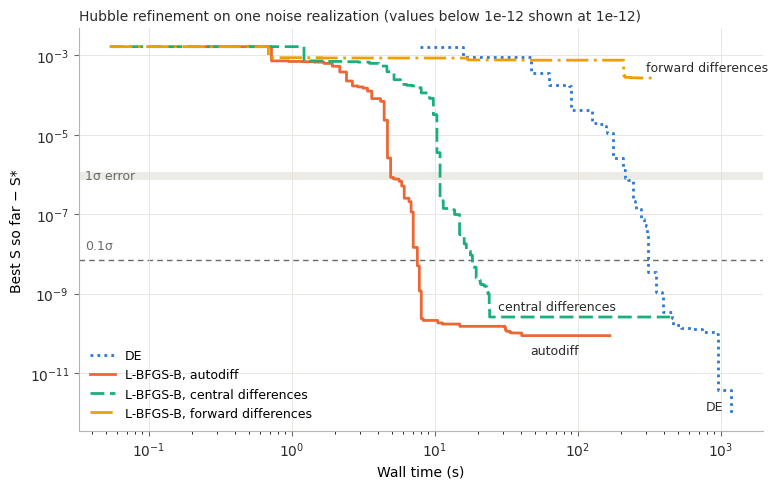

In [16]:
# categorical slots 1-4 of the default palette, in the order of LOGS
COLORS = dict(zip(LOGS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
STYLES = dict(zip(LOGS, [(0, (1, 1.5)), "-", (0, (5, 2)), (0, (8, 2, 1, 2))]))
INK, MUTED, BAND = "#2b2b2a", "#6b6a66", "#ecebe6"
FLOOR = 1e-12

fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
ax.set(xscale="log", yscale="log", xlabel="Wall time (s)", ylabel="Best S so far − S*")
ax.axhspan(DS_1SIG.min(), DS_1SIG.max(), color=BAND, lw=0, zorder=0)
ax.axhline(DS_TOL, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
# direct labels sit where each curve first reaches its final value: (label, offset in points, alignment)
LABELS = dict(zip(LOGS, [("DE", (-6, 2), "right"), ("autodiff", (6, -13), "left"),
                         ("central differences", (6, 5), "left"), ("forward differences", (6, 5), "left")]))
for name, log in LOGS.items():
    gap = np.maximum(np.minimum.accumulate(log[:, 2]) - S_STAR, FLOOR)
    ax.step(log[:, 0], gap, where="post", color=COLORS[name], ls=STYLES[name], lw=2, label=name, zorder=3)
    i = np.argmax(gap == gap[-1]) if name != "DE" else len(gap) - 1
    text, offset, ha = LABELS[name]
    ax.annotate(text, (log[i, 0], gap[i]), xytext=offset, textcoords="offset points", color=INK, fontsize=9, ha=ha)

band_labels = ax.get_yaxis_transform()   # x in axes fraction, y in data
ax.text(0.01, np.sqrt(DS_1SIG.min() * DS_1SIG.max()), "1σ error", transform=band_labels,
        color=MUTED, fontsize=9, va="center")
ax.text(0.01, DS_TOL * 1.6, "0.1σ", transform=band_labels, color=MUTED, fontsize=9, va="bottom")
ax.set_title(f"Hubble refinement on one noise realization (values below {FLOOR:g} shown at {FLOOR:g})",
             fontsize=10, color=INK, loc="left")
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.grid(True, which="major", color="#e4e3dd", lw=0.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color("#b5b4ad")
ax.tick_params(colors=MUTED, labelcolor=INK)
plt.tight_layout()
plt.show()

## 7. Findings

Results of the run above (noise seed 2026, 8 starts, 300 DE generations). Times are on this Mac, with torch in float64 on the CPU and DE run serially.

**Gradients.** With Optiland 0.6.0 as installed, the autodiff gradients of the decenters and tilts have the wrong sign and are 130–1900 times too large; only the despace gradient is close (9% low). With the reference sphere kept in the graph, autodiff agrees with central differences to three or more digits. The computed cost also jitters by about $10^{-10}$ under $10^{-12}$ changes in the parameters, so finite-difference gradients need a step much larger than SciPy's default.

**All methods except default finite differences find the same solution.** DE, autodiff L-BFGS-B and central-difference L-BFGS-B end within $0.06\sigma$ of each other (Mahalanobis distance with the noise-limited covariance). Their residuals are $(-2.0, -2.0, -0.096)\,\mu$m and $(2.4, -1.8)\times10^{-4}$ degrees, the largest $|z|$ is 1.28 and $d^2=4.6$ for 5 parameters, and the on-axis WFE is $1.5\times10^{-3}$ waves, all consistent with the noise predictions of thesis Chapter 5.

**Cost to reach that solution** (within $0.1\sigma$ of the best, `DS_TOL`):

| Method | Evaluations | Time |
|---|---|---|
| L-BFGS-B, autodiff (first start, `x0`) | 31 | 7.5 s |
| L-BFGS-B, central differences | 353 | 18 s |
| DE (about generation 78) | 5925 | 309 s |
| L-BFGS-B, forward differences (SciPy default) | not reached | — |

- **Autodiff L-BFGS-B** reached the solution about 40 times faster than DE and 2.4 times faster than central differences. All 8 starts converged to the same minimum (within $0.01\sigma$), in 58–120 evaluations (14–30 s) each; the full multi-start run took 167 s. DE took 1184 s for 300 generations, and the 2000-generation thesis protocol would take about 2.2 h at the same rate, roughly 50 times the multi-start autodiff run.
- **Central differences** reach the solution but do not stop cleanly: the jitter keeps the line search going, so each start used 814–1254 evaluations, and the multi-start run took 442 s.
- **Forward differences with SciPy's default step** stalled from every start, ending $17\sigma$ or more from the solution; even the best of them was $38\,\mu$m off in `sdx`, with a WFE of $0.013$ waves. This is the gradient that DE's L-BFGS-B polishing uses, which explains why polishing barely changed the DE solutions: here it lowered $S$ by $4\times10^{-12}$.
- The `ABNORMAL` messages mean the line search could not lower $S$ further at round-off level; they are expected at the minimum and are not failures.

**Caveats.** One noise realization of one telescope. Every start lay inside the bounds from nested sampling, so nested sampling is still needed to supply them; how the local method behaves from outside that box was not tested. The autodiff result depends on the runtime patch of `ChiefRayStrategy._create_spherical_ref`, which a later Optiland version may change or make unnecessary.
